# **Vehicle Identification Project**


### **1) Checking my current working directory**

In [1]:
import os

print(os.getcwd())

C:\Users\HP\Desktop\ml-course-following\Vehicle images dataset for the vehicle make and mo


### **2) Listing everything in the current working directory**

In [2]:
items = os.listdir()
items

['.ipynb_checkpoints',
 'chatgpt-doing-the-car-identification-like-the-dog-breed.ipynb',
 'splited_dataset',
 'vehicle-identification.ipynb',
 'vehicle_identification_model.keras',
 'vehicle_identification_model1.keras']

### **3) Inspecting the splited_dataset folder**

In [3]:
os.listdir("splited_dataset")

['test', 'train']

### **4) Inspecting the `train` and `test` folders**

In [4]:
# Inspect the training folder
print("Training folder:")
print(os.listdir("splited_dataset/train/")[:10])

# Inspect the test folder
print("\nTest folder:")
print(os.listdir("splited_dataset/test/")[:10])

Training folder:
['Daiatsu_Core', 'Daiatsu_Hijet', 'Daiatsu_Mira', 'FAW_V2', 'FAW_XPV', 'Honda_BRV', 'Honda_city_1994', 'Honda_city_2000', 'Honda_City_aspire', 'Honda_civic_1994']

Test folder:
['Daiatsu_Core', 'Daiatsu_Hijet', 'Daiatsu_Mira', 'FAW_V2', 'FAW_XPV', 'Honda_BRV', 'Honda_city_1994', 'Honda_city_2000', 'Honda_City_aspire', 'Honda_civic_1994']


### **5) Count the Vehicle classes**

In [5]:
# Get the class names from the training folder
class_names = os.listdir("splited_dataset/train/")

# Count the number of classes
print("Number of vehicle classes:", len(class_names))

# Display all class names and sort them 
print(sorted(class_names))

Number of vehicle classes: 48
['Daiatsu_Core', 'Daiatsu_Hijet', 'Daiatsu_Mira', 'FAW_V2', 'FAW_XPV', 'Honda_BRV', 'Honda_City_aspire', 'Honda_Grace', 'Honda_Vezell', 'Honda_city_1994', 'Honda_city_2000', 'Honda_civic_1994', 'Honda_civic_2005', 'Honda_civic_2007', 'Honda_civic_2015', 'Honda_civic_2018', 'KIA_Sportage', 'Suzuki_Every', 'Suzuki_Mehran', 'Suzuki_alto_2007', 'Suzuki_alto_2019', 'Suzuki_alto_japan_2010', 'Suzuki_carry', 'Suzuki_cultus_2018', 'Suzuki_cultus_2019', 'Suzuki_highroof', 'Suzuki_kyber', 'Suzuki_liana', 'Suzuki_margala', 'Suzuki_swift', 'Suzuki_wagonR_2015', 'Toyota HIACE 2000', 'Toyota_Aqua', 'Toyota_Hiace_2012', 'Toyota_Landcruser', 'Toyota_Passo', 'Toyota_Prado', 'Toyota_Vigo', 'Toyota_Vitz', 'Toyota_Vitz_2010', 'Toyota_axio', 'Toyota_corolla_2000', 'Toyota_corolla_2007', 'Toyota_corolla_2011', 'Toyota_corolla_2016', 'Toyota_fortuner', 'Toyota_pirus', 'Toyota_premio']


### **6) Check whether train and test have the same classes**

### The first 10 entries match, but we need to check whether all the classes folders match

In [6]:
train_classes = set(os.listdir("splited_dataset/train/"))
test_classes = set(os.listdir("splited_dataset/test/"))

print("Classes in train:", len(train_classes))
print("Classes in test:", len(test_classes))

print("Classes missing from test:", train_classes - test_classes)
print("Classes missing from train:", test_classes - train_classes)

Classes in train: 48
Classes in test: 48
Classes missing from test: set()
Classes missing from train: set()


### **7) Count the images in each class**
### Now we need to answer an important qtn: **`How many images do we have for each vehicle model?`**
### For e.g , perhaps `Honda_BRV` contains 100 images while `Daiatsu_Core` contains onlly 30. Such diff could affect how well the model learns each class

In [7]:
# Count the images in each training class
for class_name in sorted(train_classes):
    folder_path = os.path.join("splited_dataset", "train", class_name)
    # os.path.join() combines the folder names into a valid path. For example:splited_dataset/train/Honda_BRV
    
    num_images = len(os.listdir(folder_path)) # This lists the entries inside that class folder and counts them.

    print(f"{class_name}: {num_images} images")

Daiatsu_Core: 80 images
Daiatsu_Hijet: 44 images
Daiatsu_Mira: 81 images
FAW_V2: 29 images
FAW_XPV: 26 images
Honda_BRV: 27 images
Honda_City_aspire: 105 images
Honda_Grace: 21 images
Honda_Vezell: 38 images
Honda_city_1994: 32 images
Honda_city_2000: 69 images
Honda_civic_1994: 18 images
Honda_civic_2005: 34 images
Honda_civic_2007: 74 images
Honda_civic_2015: 31 images
Honda_civic_2018: 82 images
KIA_Sportage: 25 images
Suzuki_Every: 21 images
Suzuki_Mehran: 195 images
Suzuki_alto_2007: 132 images
Suzuki_alto_2019: 56 images
Suzuki_alto_japan_2010: 27 images
Suzuki_carry: 13 images
Suzuki_cultus_2018: 269 images
Suzuki_cultus_2019: 108 images
Suzuki_highroof: 63 images
Suzuki_kyber: 52 images
Suzuki_liana: 33 images
Suzuki_margala: 16 images
Suzuki_swift: 118 images
Suzuki_wagonR_2015: 112 images
Toyota HIACE 2000: 23 images
Toyota_Aqua: 77 images
Toyota_Hiace_2012: 72 images
Toyota_Landcruser: 17 images
Toyota_Passo: 61 images
Toyota_Prado: 21 images
Toyota_Vigo: 53 images
Toyota_Vi

### **8) Calculate the total number of training and test images**
### Let's also calculate the total number of files inside all class folders.

In [8]:
# Count training images
train_image_count = sum(
    len(os.listdir(os.path.join("splited_dataset", "train", class_name)))
    for class_name in train_classes
)


# Count test images
test_image_count = sum(
    len(os.listdir(os.path.join("splited_dataset", "test", class_name)))
    for class_name in test_classes
)

print("Total training images:", train_image_count)
print("Total test images:", test_image_count)
print("Combined total:", train_image_count + test_image_count)

Total training images: 3106
Total test images: 752
Combined total: 3858


### **9) Check the distribution of images across classes**
### Before preparing the images, let's determine whether some vehicle classes have far more images than others.

In [9]:
import pandas as pd

# Store the number of images in each training class
train_counts = {}

for class_name in sorted(train_classes): # Loops through each vehicle class and counts its files.
    folder_path = os.path.join("splited_dataset", "test", class_name)
    train_counts[class_name] = len(os.listdir(folder_path)) #Stores each class name alongside its 
    # image count.

# Convert the dictionary into pandas Series
train_distribution = pd.Series(train_counts) # Converts the dictionary into a pandas Series so we 
# can analyse the distribution.

print(train_counts)

# Display summary statistics
print(train_distribution.describe())

{'Daiatsu_Core': 20, 'Daiatsu_Hijet': 10, 'Daiatsu_Mira': 20, 'FAW_V2': 7, 'FAW_XPV': 6, 'Honda_BRV': 6, 'Honda_City_aspire': 26, 'Honda_Grace': 5, 'Honda_Vezell': 9, 'Honda_city_1994': 7, 'Honda_city_2000': 17, 'Honda_civic_1994': 4, 'Honda_civic_2005': 8, 'Honda_civic_2007': 18, 'Honda_civic_2015': 7, 'Honda_civic_2018': 20, 'KIA_Sportage': 6, 'Suzuki_Every': 5, 'Suzuki_Mehran': 48, 'Suzuki_alto_2007': 32, 'Suzuki_alto_2019': 14, 'Suzuki_alto_japan_2010': 6, 'Suzuki_carry': 3, 'Suzuki_cultus_2018': 67, 'Suzuki_cultus_2019': 27, 'Suzuki_highroof': 15, 'Suzuki_kyber': 12, 'Suzuki_liana': 8, 'Suzuki_margala': 4, 'Suzuki_swift': 29, 'Suzuki_wagonR_2015': 27, 'Toyota HIACE 2000': 5, 'Toyota_Aqua': 19, 'Toyota_Hiace_2012': 17, 'Toyota_Landcruser': 4, 'Toyota_Passo': 15, 'Toyota_Prado': 5, 'Toyota_Vigo': 13, 'Toyota_Vitz': 20, 'Toyota_Vitz_2010': 11, 'Toyota_axio': 4, 'Toyota_corolla_2000': 9, 'Toyota_corolla_2007': 20, 'Toyota_corolla_2011': 31, 'Toyota_corolla_2016': 67, 'Toyota_fortuner'

### **10) Identify the classes with the fewest and most images**

In [10]:
print("10 classes with the fewest images:")
print(train_distribution.sort_values().head(10))

print("\n10 classes with the most images:")
print(train_distribution.sort_values(ascending=False).head(10))

10 classes with the fewest images:
Suzuki_carry         3
Honda_civic_1994     4
Suzuki_margala       4
Toyota_Landcruser    4
Toyota_axio          4
Toyota_premio        4
Suzuki_Every         5
Honda_Grace          5
Toyota_Prado         5
Toyota HIACE 2000    5
dtype: int64

10 classes with the most images:
Toyota_corolla_2016    67
Suzuki_cultus_2018     67
Suzuki_Mehran          48
Suzuki_alto_2007       32
Toyota_corolla_2011    31
Suzuki_swift           29
Suzuki_wagonR_2015     27
Suzuki_cultus_2019     27
Honda_City_aspire      26
Daiatsu_Core           20
dtype: int64


### **11) Visualise the class distribution**
### A bar chart makes this imbalance easier to see.

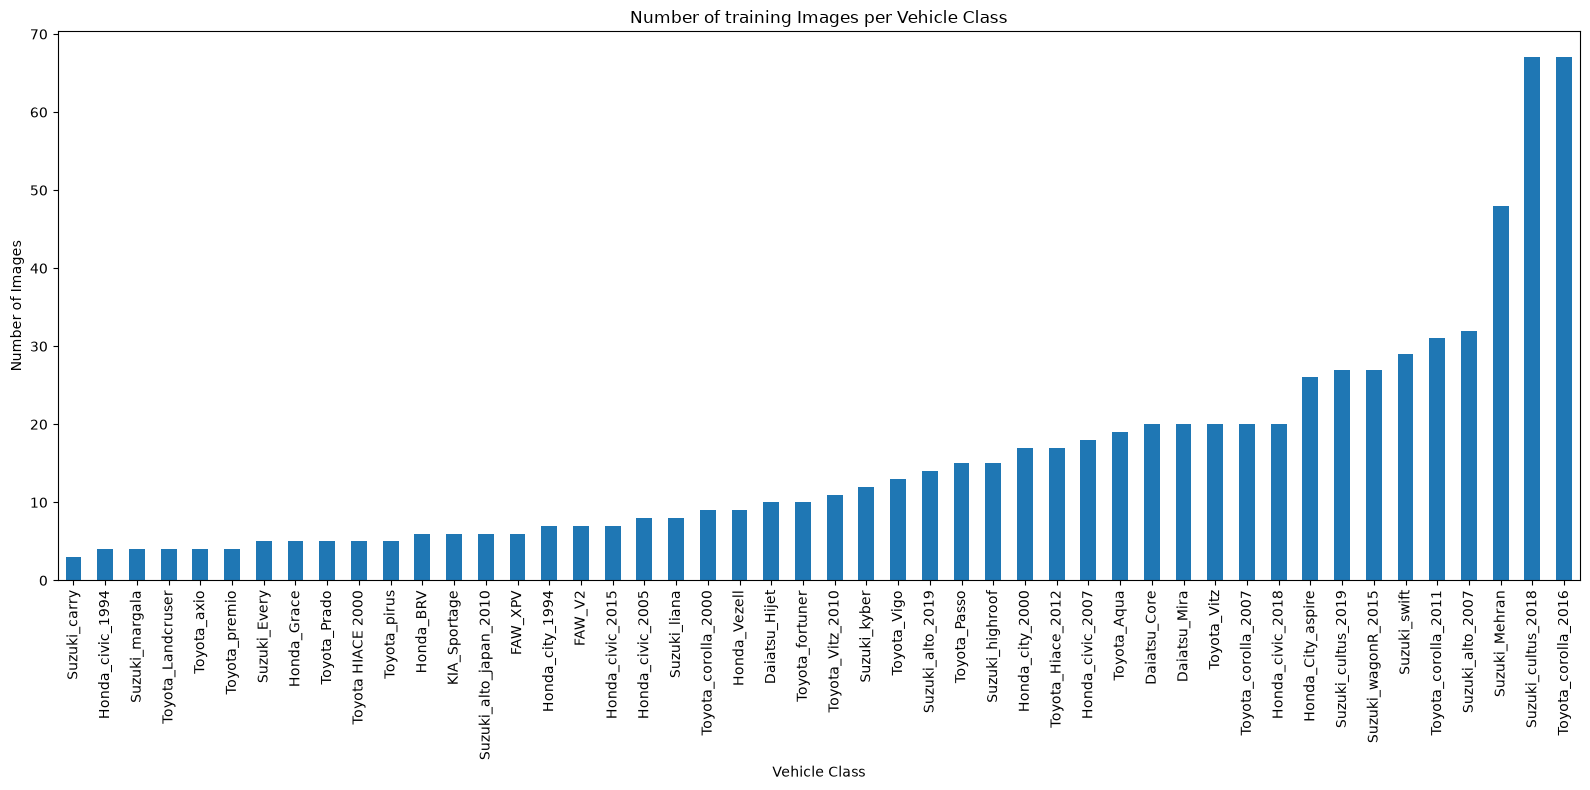

In [11]:
import matplotlib.pyplot as plt

# Sort the classes from fewest to most images
train_distribution = train_distribution.sort_values()

# Plot the distribution
plt.figure(figsize=(16, 8))
train_distribution.plot(kind="bar")

plt.title("Number of training Images per Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90);
plt.tight_layout();
# plt.show()

### **12) Display the actual vehicle Images**
### Now let's move from counting images to understanding what the model will see.

### **What are we learning from this step?**
#### **We want to see:**
#### 1. Whether the files are valid images.
#### 2. Whether the vehicles are clearly visible.
#### 3. Whether images have different dimensions or orientations.
#### 4. Whether the photos have varied backgrounds, angles, or lighting.
#### 5. Whether two vehicle models look visually similar.

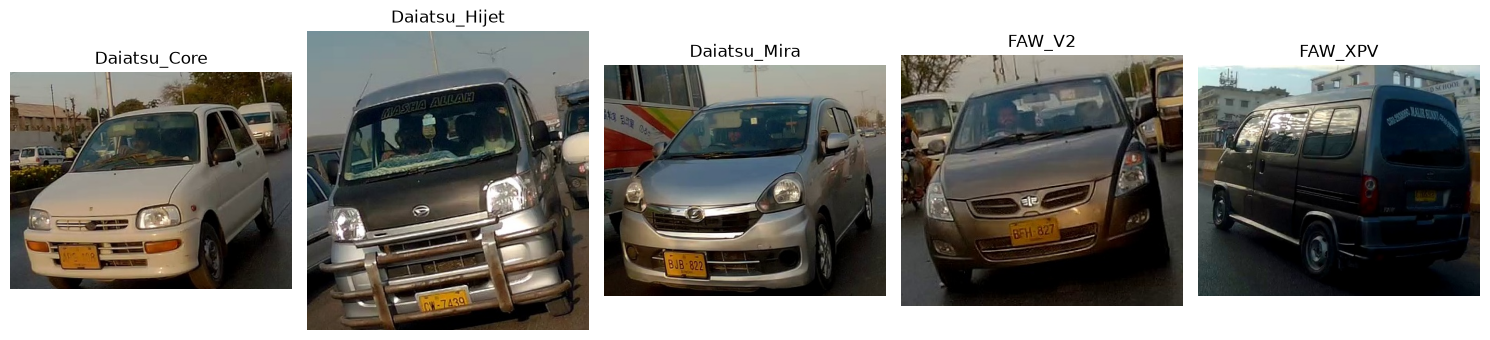

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Select the first five classes
sample_classes = sorted(train_classes)[:5]

plt.figure(figsize=(15, 5))

for i, class_name in enumerate(sample_classes):
    # print(f"{i}: {class_name}") 

    # 1) Get the folder path
    folder_path = os.path.join(
         "splited_dataset", "train", class_name
    )
    
    # print(folder_path)
    
    # 2) Get the first image in the folder
    image_name = os.listdir(folder_path)[0]
    image_path = os.path.join(folder_path, image_name)
    
    # print(f"{image_path}: {image_name}")
    
    # 3) Open and display the image
    image = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout();
# plt.show()

### **13) Inspect the image dimensions**

In [13]:
from PIL import Image
import os

# a) Select the first 5 images
# 1) Get the classes or folder where the 5 images are located 
sample_classes = sorted(train_classes)[:5]
# print(sample_classes)

# 2) Looping thru the folder/classes to create the folder path of the images
for class_name in sample_classes:
    folder_path = os.path.join(
        "splited_dataset", "train", class_name
    )
    # print(folder_path)

    # b) Get the image path of the first image in a folder/class
    # 1) Select the first image name in each folder/class
    image_name = os.listdir(folder_path)[0]
    # print(image_name)
    # 2) Form the image path from the selected image name
    image_path = os.path.join(folder_path, image_name)
    # print(image_path)

    # c) Open the image
    image = Image.open(image_path)
    # print(image)

    # d) Display image dimensions
    print(class_name, image.size, image.format)

Daiatsu_Core (397, 305) JPEG
Daiatsu_Hijet (363, 385) JPEG
Daiatsu_Mira (422, 345) JPEG
FAW_V2 (304, 270) JPEG
FAW_XPV (509, 416) JPEG


### **14) Our next step: Check image dimensions across the dataset**
### So far, we have inspected only five images. We cannot conclude that all images have different dimensions based on those five samples.

In [14]:
from collections import Counter
from PIL import Image
import os

# 1) Store the dimensions of all training images
image_sizes = []

# 2) Looping thru the folder/classes to create the folder path of the images
for class_name in sorted(train_classes):
    folder_path = os.path.join(
        "splited_dataset", "train", class_name
    )

    # 3) Looping over the image names to form a the image path
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)

        # 4) Accessing the image and appending the size to the empty list we created above(image_sizes)
        # 1) can be written like:
        with Image.open(image_path) as image:
            image_sizes.append(image.size)
        # 2) Or like this:
        image_sizes.append(Image.open(image_path).size)
        

# 5) Count how frequently each dimension occurs
size_counts = Counter(image_sizes)


print("Total images inspected:", len(image_sizes))
print("Number of unique image dimensions:", len(size_counts))

# 6) Getting the size of 5 most common images
print("\nFive most common dimensions:")
for size, count in size_counts.most_common(5):
    print(f"{size}: {count} images")

Total images inspected: 6212
Number of unique image dimensions: 2959

Five most common dimensions:
(355, 271): 8 images
(393, 267): 6 images
(342, 279): 6 images
(374, 265): 6 images
(394, 277): 6 images


### **15) Let's investigate the difference in `total_folders`, `total_files`, `total_images`**

In [15]:
import os

train_path = "splited_dataset/train"

total_files = 0
total_images = 0
total_folders = 0

for class_name in os.listdir(train_path):
    folder_path = os.path.join(train_path, class_name)

    if os.path.isdir(folder_path):
        total_folders += 1

        files = os.listdir(folder_path)
        total_files += len(files)

        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                total_images += 1

print("Number of folders:", total_folders)
print("Total files:", total_files)
print("Total image files:", total_images)

Number of folders: 48
Total files: 3106
Total image files: 3106


### **16) Understand how the labels are assigned**

### Before preparing the images for the model, let's look at how the dataset identifies each vehicle. In your dataset, the folder name is the label. For example, an image inside `Daiatsu_Core` belongs to the `Daiatsu_Core` class.

In [16]:
import os

train_path = "splited_dataset/train"

# Get all vehicle class names
class_names = sorted(os.listdir(train_path))

print("Number of classes:", len(class_names))
print("\nFirst 10 vehicle classes:")

for class_name in class_names[:10]:
    print(class_name)

Number of classes: 48

First 10 vehicle classes:
Daiatsu_Core
Daiatsu_Hijet
Daiatsu_Mira
FAW_V2
FAW_XPV
Honda_BRV
Honda_City_aspire
Honda_Grace
Honda_Vezell
Honda_city_1994


### **16) Find the missing class**

In [17]:
counted_classes = [
    "Daiatsu_Core", "Daiatsu_Hijet", "Daiatsu_Mira",
    "FAW_V2", "FAW_XPV", "Honda_BRV",
    "Honda_City_aspire", "Honda_Grace", "Honda_Vezell",
    "Honda_city_1994", "Honda_city_2000", "Honda_civic_1994",
    "Honda_civic_2005", "Honda_civic_2007", "Honda_civic_2015",
    "Honda_civic_2018", "KIA_Sportage", "Suzuki_Every",
    "Suzuki_Mehran", "Suzuki_alto_2007", "Suzuki_alto_2019",
    "Suzuki_alto_japan_2010", "Suzuki_carry", "Suzuki_cultus_2018",
    "Suzuki_cultus_2019", "Suzuki_highroof", "Suzuki_kyber",
    "Suzuki_liana", "Suzuki_margala", "Suzuki_swift",
    "Suzuki_wagonR_2015", "Toyota HIACE 2000", "Toyota_Aqua",
    "Toyota_Hiace_2012", "Toyota_Landcruser", "Toyota_Passo",
    "Toyota_Prado", "Toyota_Vigo", "Toyota_Vitz",
    "Toyota_Vitz_2010", "Toyota_axio", "Toyota_corolla_2000",
    "Toyota_corolla_2007", "Toyota_corolla_2011",
    "Toyota_corolla_2016", "Toyota_fortuner", "Toyota_pirus",
    "Toyota_premio"
]

print("Number counted:", len(counted_classes))
print("Missing class:", set(class_names) - set(counted_classes))

Number counted: 48
Missing class: set()


# **Preparation of our Data**

In [18]:
import tensorflow as tf
import tensorflow_hub as hub

print("TensorFlow version:", tf.__version__)
print("TensorFlow Hub version:", hub.__version__)

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version



TensorFlow version: 2.21.0
TensorFlow Hub version: 0.16.1


### **1) Split the training data**

In [19]:
print("train_path exists:", "train_path" in globals())
print("val_path exists:", "val_path" in globals())
print("train_ds exists:", "train_ds" in globals())
print("val_ds exists:", "val_ds" in globals())

train_path exists: True
val_path exists: False
train_ds exists: False
val_ds exists: False


In [20]:
print(train_path)

splited_dataset/train


### The train_path correctly points to splited_dataset/train, which contains your 3,106 training images.

### Now we need to create a validation set from those training images. We'll keep the existing splited_dataset/test folder separate so it can be used for the final evaluation.

### Since the images are already arranged into folders by vehicle class, the simplest approach is to use TensorFlow's image_dataset_from_directory() function. It can load the images, infer their labels from the folder names, resize them, and divide the training data into training and validation subsets.

In [21]:
def create_train_val_datasets(
    train_path,
    img_size=(224, 224),
    batch_size=32,
    seed=42
):
    """
    Loads images from class folders and creates training
    and validation datasets.
    """

    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_path,
        validation_split=0.2,
        subset="training",
        seed=seed,
        image_size=img_size,
        batch_size=batch_size
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        train_path,
        validation_split=0.2,
        subset="validation",
        seed=seed,
        image_size=img_size,
        batch_size=batch_size
    )

    return train_ds, val_ds

In [22]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


train_ds, val_ds = create_train_val_datasets(
    train_path=train_path,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 3106 files belonging to 48 classes.
Using 2485 files for training.
Found 3106 files belonging to 48 classes.
Using 621 files for validation.


### **2) Check the class names and image shapes**

In [23]:
class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print("Class names:", class_names)

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Number of classes: 48
Class names: ['Daiatsu_Core', 'Daiatsu_Hijet', 'Daiatsu_Mira', 'FAW_V2', 'FAW_XPV', 'Honda_BRV', 'Honda_City_aspire', 'Honda_Grace', 'Honda_Vezell', 'Honda_city_1994', 'Honda_city_2000', 'Honda_civic_1994', 'Honda_civic_2005', 'Honda_civic_2007', 'Honda_civic_2015', 'Honda_civic_2018', 'KIA_Sportage', 'Suzuki_Every', 'Suzuki_Mehran', 'Suzuki_alto_2007', 'Suzuki_alto_2019', 'Suzuki_alto_japan_2010', 'Suzuki_carry', 'Suzuki_cultus_2018', 'Suzuki_cultus_2019', 'Suzuki_highroof', 'Suzuki_kyber', 'Suzuki_liana', 'Suzuki_margala', 'Suzuki_swift', 'Suzuki_wagonR_2015', 'Toyota HIACE 2000', 'Toyota_Aqua', 'Toyota_Hiace_2012', 'Toyota_Landcruser', 'Toyota_Passo', 'Toyota_Prado', 'Toyota_Vigo', 'Toyota_Vitz', 'Toyota_Vitz_2010', 'Toyota_axio', 'Toyota_corolla_2000', 'Toyota_corolla_2007', 'Toyota_corolla_2011', 'Toyota_corolla_2016', 'Toyota_fortuner', 'Toyota_pirus', 'Toyota_premio']
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


### **3) Improve data loading performance**
### Before building the model, we can make the datasets load more efficiently using TensorFlow's cache() and prefetch().

In [24]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

### **4) Understand transfer learning**

### Rather than training a neural network from scratch, we'll use transfer learning. This means starting with a model that has already learned useful visual features from millions of images, then adapting it to recognize your 48 vehicle classes.

### We'll use **`MobileNetV2`** as our starting model. It is a pretrained image-recognition model designed to be relatively lightweight.

### **5) Preprocess the images**
### The current image batches contain pixel values ranging approximately from 0 to 255. `MobileNetV2's` pretrained weights expect these values to be scaled to approximately -1 to 1

In [25]:
# Get MobileNetV2's image preprocessing function
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Preprocess the training images
train_ds = train_ds.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=AUTOTUNE
) # preprocess_input scales the image pixels into the range expected by MobileNetV2.

# Preprocess the validation images
val_ds = val_ds.map(
    # .map() applies the preprocessing function to each batch as the dataset is read.
    lambda images, labels: (preprocess_input(images), labels),
    # images are transformed, but labels remain unchanged.
    num_parallel_calls=AUTOTUNE # AUTOTUNE lets TensorFlow optimize how it processes the batches.
) 

### **6) Load the pretrained model**

In [26]:
# Load MobileNetV2 pretrained on ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), # input_shape=(224, 224, 3): the model receives 224 × 224 RGB images.
    include_top=False, # include_top=False: removes the original final classification layers, because
    # they were designed for ImageNet's 1,000 classes, not our 48 vehicle classes.
    weights="imagenet", # weights="imagenet": loads weights learned from the ImageNet dataset.
    pooling="avg" # pooling="avg": converts the extracted image features into a single feature vector.
)

# Freeze the pretrained layers
base_model.trainable = False # freezes the pretrained layers so their learned weights won't change during 
# our initial training.

In [27]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 112, 112, 32)      │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 112, 112, 32)      │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 112, 112, 32)      │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 112, 112, 32)      │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 112, 112, 32)      │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 112, 112, 32)      │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 112, 112, 16)      │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 112, 112, 16)      │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 112, 112, 96)      │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 112, 112, 96)      │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 112, 112, 96)      │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 113, 113, 96)      │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 56, 56, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

### **7) Build the Complete Model**

In [28]:
# Create the model input
inputs = tf.keras.Input(shape=(224, 224, 3)) # accepts a 224 × 224 RGB image.

# Extract features using MobileNetV2
x = base_model(inputs, training=False) # extracts the visual features.

# Add a classification layer for our 48 classes
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
# Dense(len(class_names), activation="softmax") produces 48 scores, one for each vehicle class. 
# Softmax converts them into probabilities that sum to 1.

# Combine everything into one model
model = tf.keras.Model(inputs, outputs) # connects these parts into one complete model.

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 1280)                │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 48)                  │          61,488 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,319,472 (8.85 MB)

 Trainable params: 61,488 (240.19 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### **8) Compile the model**
#### **Before training, we must configure three things:**
#### - **Optimizer:** How the model updates its trainable parameters.
#### - **Loss function:** How we measure the error in its predictions.
#### - **Metrics:** What we use to monitor performance.

In [29]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### **9) Creating an `EarlyStopping callback`**
### EarlyStopping callback that monitors the model during training and can stop training when the monitored metric stops improving.

In [30]:
# Create an early stopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", # Monitor the loss on the validation dataset.
    patience=3, # Allow three consecutive epochs without improvement before stopping.
    restore_best_weights=True # Restore the model weights from the epoch with the lowest validation loss.
)

### **10) train the Model and validate Its Performance**
#### I commented the below bcos we have already fitted the model and stored it

In [31]:
EPOCHS = 10 # We chose 10 epochs as a starting point, not because 10 is always the best number.
# The model goes through those images ten times.

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

C:\Users\HP\miniconda3\envs\dog-vision\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 62s 743ms/step - accuracy: 0.2507 - loss: 3.0785 - val_accuracy: 0.3784 - val_loss: 2.4665
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 56s 716ms/step - accuracy: 0.5123 - loss: 1.9799 - val_accuracy: 0.5056 - val_loss: 1.9641
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 57s 731ms/step - accuracy: 0.6805 - loss: 1.4560 - val_accuracy: 0.5862 - val_loss: 1.6975
Epoch 4/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 56s 715ms/step - accuracy: 0.7771 - loss: 1.1344 - val_accuracy: 0.6618 - val_loss: 1.4920
Epoch 5/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 56s 712ms/step - accuracy: 0.8306 - loss: 0.9216 - val_accuracy: 0.6860 - val_loss: 1.3614
Epoch 6/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 58s 746ms/step - accuracy: 0.8736 - loss: 0.7556 - val_accuracy: 0.6940 - val_loss: 1.2902
Epoch 7/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 80s 720ms/step - accuracy: 0.9030 - loss: 0.6379 - val_accuracy: 0.7053 - val_loss: 1.2314
Epoch 8/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 56s 716ms/step - accuracy: 0.9284 - loss: 0.5433 - val_accu

### **11) Save the trained Model**

In [45]:
# Save the trained model
model.save("vehicle_identification_model.keras")

### **12) Load the Saved Model**

In [46]:
# Load the saved model
model = tf.keras.models.load_model(
    "vehicle_identification_model.keras"
)

### **13) Plot the training history**
#### I also commented the below bcos the code in no. `10` will affect it

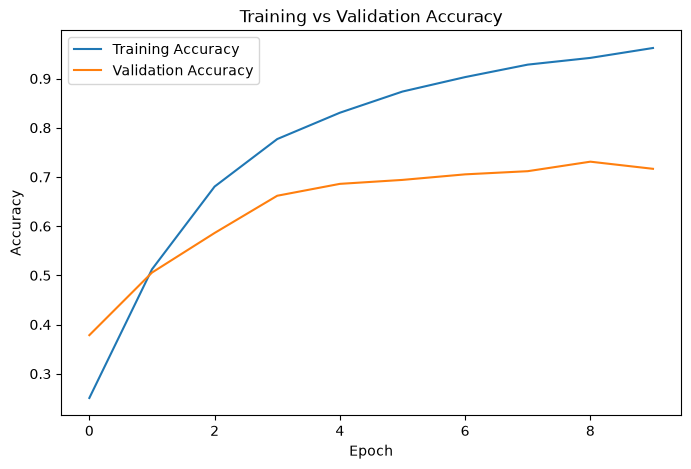

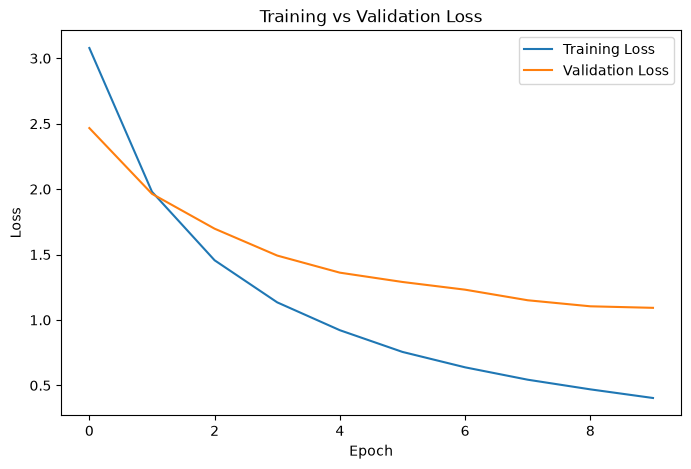

In [47]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### **Are we overfitting?**
#### There are signs of overfitting, or at least a growing generalization gap.

#### Look at these two results:
#### - Training accuracy increased from 24.59% to 95.81%.
#### - Validation accuracy increased to 73.11% at epoch 9, then fell to 71.66% at epoch 10.
#### The gap between training and validation accuracy at epoch 10 is about 23.99 percentage points.

#### This suggests that the model is learning the training images much better than it performs on images it has not trained on. However, one small drop in validation accuracy does not, by itself, prove severe overfitting

### **What about validation loss?**
#### Validation loss decreased from 2.4665 in epoch 1 to 1.0926 in epoch 10.

#### That is encouraging: the model's validation loss continued improving, even when validation accuracy dipped slightly in the final epoch.

### **14) Load the test dataset**

In [35]:
# Load the test dataset
test_path = "splited_dataset/test"

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path, # Points to our separate test folder.
    image_size=IMG_SIZE, # Resizes images to 224 × 224 pixels, just like the training images.
    batch_size=BATCH_SIZE, # Loads images in batches of 32.
    shuffle=False # Loads images in batches of 32.
)

Found 752 files belonging to 48 classes.


### **15) Preprocess the test images**

In [36]:
# Apply MobileNetV2 preprocessing to the test images
test_ds = test_ds.map(
    lambda images, labels: (preprocess_input(images), labels),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

### **16) Evaluate the Model on the test dataset**

In [37]:
# Evaluate the model on the test dataset
test_loss, test_accuracy = model.evaluate(test_ds) 
# measures the model's performance on the test images.

print(f"Test Loss: {test_loss:.4f}") 
# test_loss measures how well the predicted probabilities match the correct vehicle labels.
print(f"Test Accuracy: {test_accuracy:.4f}") 
# test_accuracy measures the proportion of test images classified correctly.
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 562ms/step - accuracy: 0.7287 - loss: 1.0910
Test Loss: 1.0910
Test Accuracy: 0.7287
Test Accuracy: 72.87%


#### The model correctly classified approximately 559 of the 752 test images and incorrectly classified approximately 193. The exact count may differ slightly because the accuracy is rounded.
#### - Test accuracy of **`72.87`%**: The model predicts the correct vehicle class for roughly **`73`** out of every **`100`** test images.
#### - Test loss of 1.0910: This measures how well the model's predicted probabilities align with the correct labels. Lower is generally better when comparing models evaluated with the same loss function.

### **Is this a good result?**
#### For our first baseline model, it is an encouraging result. We used a pretrained MobileNetV2 model and trained a new classification layer for 48 vehicle classes.

#### Our validation accuracy peaked at 71.66%, while test accuracy is 72.87%. These results are reasonably close, suggesting that performance on the separate test set is consistent with validation performance.

#### However, overall accuracy does not tell us whether the model performs equally well for every vehicle class. Our dataset is imbalanced, so some classes may be much harder to identify than others.

### **17) Examine individual predictions**
#### Let's display some test images alongside the model's predictions and the correct labels. This will help us see what the model gets right and wrong.

In [38]:
# Get one batch of test images and their true labels
for images, labels in test_ds.take(1):
    predictions = model.predict(images)

# Convert prediction probabilities into class indices
predicted_labels = tf.argmax(predictions, axis=1)

print("True labels:", labels.numpy()[:10])
print("Predicted labels:", predicted_labels.numpy()[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
True labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [ 0  0 18 23 35  0  0  0  0  0]


### **For the first 10 images:**
#### - The model correctly classified images 1, 2, 6, 7, 8, 9 and 10 as class 0.
#### - It incorrectly classified images 3, 4 and 5, predicting classes 18, 23 and 23 instead.
#### That means it got 7 out of 10 correct (70%) in this particular batch. This is only a small sample, not the overall test accuracy.

### **18) Find out what the numbers mean**
#### **The reason for the below code is:**
#### This converts the numerical class indices into actual vehicle class names, such as Daiatsu_Core or Toyota_corolla_2016.

### **Why is this useful?**
#### It lets us see exactly which vehicle classes the model confuses with one another.

In [39]:
# Display the predicted and true vehicle names
for i in range(10):
    print(
        f"Image {i + 1}: "
        f"True = {class_names[labels[i].numpy()]}, "
        f"Predicted = {class_names[predicted_labels[i].numpy()]}"
    )

Image 1: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 2: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 3: True = Daiatsu_Core, Predicted = Suzuki_Mehran
Image 4: True = Daiatsu_Core, Predicted = Suzuki_cultus_2018
Image 5: True = Daiatsu_Core, Predicted = Toyota_Passo
Image 6: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 7: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 8: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 9: True = Daiatsu_Core, Predicted = Daiatsu_Core
Image 10: True = Daiatsu_Core, Predicted = Daiatsu_Core


#### Now we can see exactly which vehicle classes our model confused.

### **From your output:**
#### - Correct: 7 images were classified as Daiatsu_Core.
#### - Incorrect: 3 images were classified as other vehicles:
 * #### Image 3 → Suzuki_Mehran
 * #### Images 4 and 5 → Suzuki_cultus_2018
#### This tells us the model sometimes confuses Daiatsu_Core with other vehicle models. We would need to inspect the actual images to investigate why.

### **19) Display the images with their predictions**

#### Let's create a function to display 10 images, their true labels, and their predicted labels. 

In [40]:
import matplotlib.pyplot as plt
import numpy as np

def show_test_predictions(images, true_labels, predicted_labels, class_names, n=10):
    """
    Displays test images with their true and predicted vehicle classes.
    """
    plt.figure(figsize=(18, 12))

    for i in range(min(n, len(images))):
        plt.subplot(2, 5, i + 1)

        # Convert image values from [-1, 1] back to [0, 1]
        image = (images[i].numpy() + 1) / 2

        plt.imshow(np.clip(image, 0, 1))

        true_name = class_names[int(true_labels[i].numpy())]
        pred_name = class_names[int(predicted_labels[i].numpy())]

        # Green means correct; red means incorrect
        color = "green" if true_name == pred_name else "red"

        plt.title(
            f"True: {true_name}\nPred: {pred_name}",
            color=color,
            fontsize=12
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

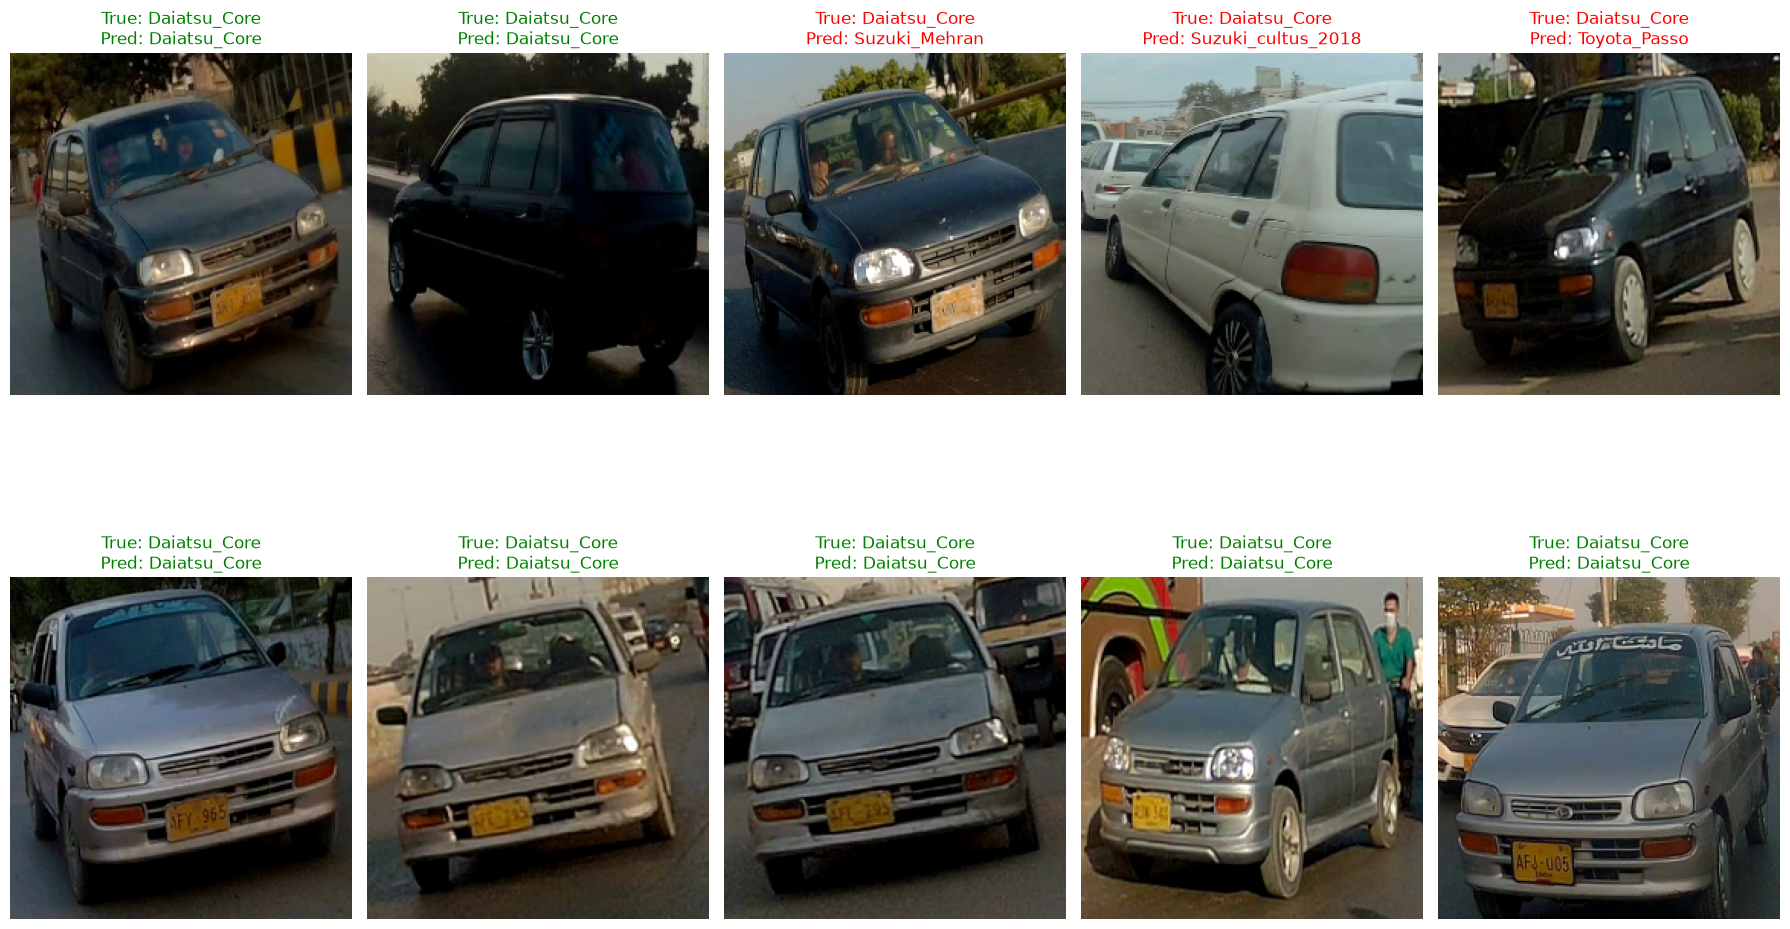

In [41]:
show_test_predictions(
    images,
    labels,
    predicted_labels,
    class_names,
    n=10
)